# Kebab Storm Personal Health Analytics

This notebook reads the scenario from Vault and returns a read-only Spark DataFrame. Decrypted personal identifiers are never requested or displayed. It demonstrates aggregate analysis and an illustrative Spark ML regression over synthetic, non-identifying clinical measurements.

In [1]:
import os

from pyspark.sql import SparkSession, functions as F
from kebab_storm_analytics import read_dataset

spark = SparkSession.builder.master("local[*]").appName("Kebab Storm Health Analytics").getOrCreate()

# The launcher supplies these environment variables. The fallback address is valid only
# between containers on the private local demo network. Never put a real token in a notebook.
vault_config = {
    "vault_addr": os.environ.get("VAULT_ADDR", "http://kebab-storm-vault:8200"),
    "vault_token": os.environ["VAULT_TOKEN"],
    "vault_secret": os.environ.get(
        "KEBAB_STORM_SCENARIO_SECRET",
        "secret/kebab-storm/personal-health-records",
    ),
    "allow_insecure_vault_http": True,  # local Docker demo only
    "data_location": os.environ.get(
        "KEBAB_STORM_DATA_LOCATION",
        "/home/jovyan/work/kebab_storm/demo/output",
    ),
    "storage_provider": os.environ.get("KEBAB_STORM_STORAGE_PROVIDER", "parquet"),
}

## Encrypted read (default)

No decryption is requested here. Every scenario field marked `is_encrypted: true` remains a binary column.

In [2]:
encrypted_health = read_dataset(spark, **vault_config)
encrypted_health.printSchema()

root
 |-- PATIENT_RECORD_ID: binary (nullable = true)
 |-- PATIENT_NAME: binary (nullable = true)
 |-- BIOLOGICAL_SEX: binary (nullable = true)
 |-- AGE: integer (nullable = true)
 |-- VISIT_COUNT_TEXT: string (nullable = true)
 |-- MEDICATION_COUNT: byte (nullable = true)
 |-- HEIGHT_CM: binary (nullable = true)
 |-- WEIGHT_KG_TEXT: string (nullable = true)
 |-- BMI: double (nullable = true)
 |-- HEART_RATE: short (nullable = true)
 |-- SYSTOLIC_BP: short (nullable = true)
 |-- DIASTOLIC_BP: short (nullable = true)
 |-- GLUCOSE_LEVEL: binary (nullable = true)
 |-- RISK_SCORE_TEXT: string (nullable = true)
 |-- DAILY_STEPS: integer (nullable = true)
 |-- INSURANCE_NUMBER_TEXT: binary (nullable = true)
 |-- BIRTH_DATE: binary (nullable = true)
 |-- LAST_CHECKUP_TEXT: string (nullable = true)
 |-- APPOINTMENT_AT: binary (nullable = true)
 |-- DISCHARGE_EPOCH_SECONDS: long (nullable = true)
 |-- RECORD_CREATED_AT: binary (nullable = true)
 |-- HAS_CONSENT: boolean (nullable = true)
 |-- A

## Selective decryption (recommended)

Only the mapped fields required by this aggregation are decrypted. Other protected values, including patient identifiers and names, stay encrypted.

In [3]:
health = read_dataset(
    spark,
    **vault_config,
    crypto_action="decrypted",
    decrypt_columns=["BIOLOGICAL_SEX", "GLUCOSE_LEVEL"],
    include_soft_deleted=False,
)

health.printSchema()

root
 |-- PATIENT_RECORD_ID: binary (nullable = true)
 |-- PATIENT_NAME: binary (nullable = true)
 |-- BIOLOGICAL_SEX: string (nullable = true)
 |-- AGE: integer (nullable = true)
 |-- VISIT_COUNT_TEXT: string (nullable = true)
 |-- MEDICATION_COUNT: byte (nullable = true)
 |-- HEIGHT_CM: binary (nullable = true)
 |-- WEIGHT_KG_TEXT: string (nullable = true)
 |-- BMI: double (nullable = true)
 |-- HEART_RATE: short (nullable = true)
 |-- SYSTOLIC_BP: short (nullable = true)
 |-- DIASTOLIC_BP: short (nullable = true)
 |-- GLUCOSE_LEVEL: float (nullable = true)
 |-- RISK_SCORE_TEXT: string (nullable = true)
 |-- DAILY_STEPS: integer (nullable = true)
 |-- INSURANCE_NUMBER_TEXT: binary (nullable = true)
 |-- BIRTH_DATE: binary (nullable = true)
 |-- LAST_CHECKUP_TEXT: string (nullable = true)
 |-- APPOINTMENT_AT: binary (nullable = true)
 |-- DISCHARGE_EPOCH_SECONDS: long (nullable = true)
 |-- RECORD_CREATED_AT: binary (nullable = true)
 |-- HAS_CONSENT: boolean (nullable = true)
 |-- AC

In [4]:
health.groupBy("BIOLOGICAL_SEX").agg(
    F.count("*").alias("PATIENT_COUNT"),
    F.round(F.avg("AGE"), 1).alias("AVERAGE_AGE"),
    F.round(F.avg("GLUCOSE_LEVEL"), 1).alias("AVERAGE_GLUCOSE"),
).orderBy("BIOLOGICAL_SEX").show(truncate=False)

+--------------+-------------+-----------+---------------+
|BIOLOGICAL_SEX|PATIENT_COUNT|AVERAGE_AGE|AVERAGE_GLUCOSE|
+--------------+-------------+-----------+---------------+
|Female        |24625        |49.9       |91.0           |
|Intersex      |163          |49.3       |90.4           |
|Male          |24324        |49.5       |90.7           |
|Not specified |888          |49.9       |91.5           |
+--------------+-------------+-----------+---------------+



## Spark ML regression with selective decryption

This illustrative model predicts the encrypted `GLUCOSE_LEVEL` after decrypting only that analytical target. Its features are non-identifying clinical measurements already stored as typed columns. No patient names, identifiers, insurance values, or contact details enter the model or chart. The dataset is synthetic, so these metrics have no clinical meaning and the model must not be used for medical decisions.

In [5]:
from pyspark.ml import Pipeline
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression

feature_columns = [
    "AGE",
    "BMI",
    "HEART_RATE",
    "SYSTOLIC_BP",
    "DIASTOLIC_BP",
    "MEDICATION_COUNT",
    "DAILY_STEPS",
    "IS_SMOKER",
]

model_data = health.select(
    F.col("GLUCOSE_LEVEL").cast("double").alias("label"),
    *[F.col(name).cast("double").alias(name) for name in feature_columns],
).dropna()

training_data, test_data = model_data.randomSplit([0.8, 0.2], seed=42)
pipeline = Pipeline(stages=[
    VectorAssembler(inputCols=feature_columns, outputCol="features"),
    LinearRegression(featuresCol="features", labelCol="label", regParam=0.05),
])
regression_model = pipeline.fit(training_data)
predictions = regression_model.transform(test_data).cache()

In [6]:
metrics = {
    metric: RegressionEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric,
    ).evaluate(predictions)
    for metric in ("rmse", "mae", "r2")
}

print(f"Training rows: {training_data.count():,}")
print(f"Test rows:     {predictions.count():,}")
print(f"RMSE:          {metrics['rmse']:.2f}")
print(f"MAE:           {metrics['mae']:.2f}")
print(f"R²:            {metrics['r2']:.3f}")

Training rows: 39,982
Test rows:     9,814
RMSE:          18.59
MAE:           12.50
R²:            0.169


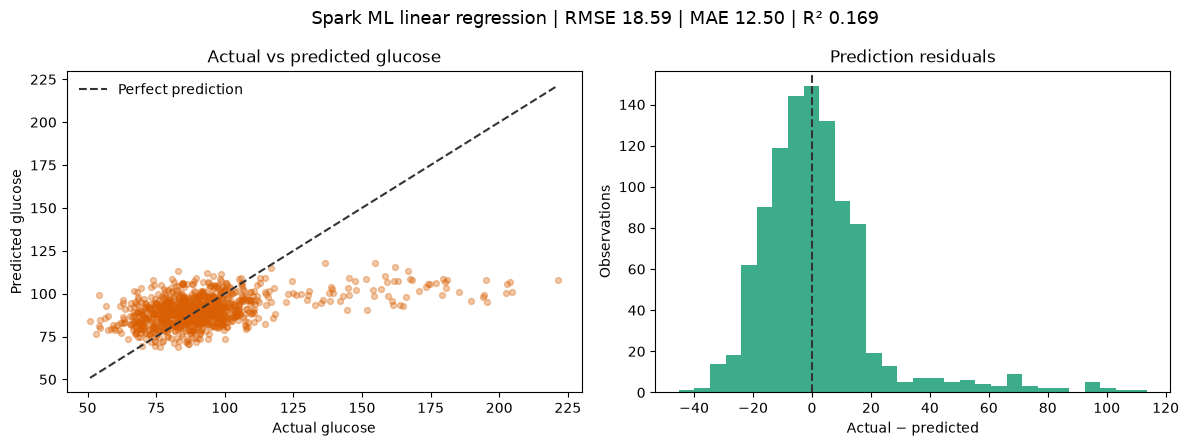

DataFrame[label: double, AGE: double, BMI: double, HEART_RATE: double, SYSTOLIC_BP: double, DIASTOLIC_BP: double, MEDICATION_COUNT: double, DAILY_STEPS: double, IS_SMOKER: double, features: vector, prediction: double]

In [7]:
import matplotlib.pyplot as plt

plot_sample = (
    predictions
    .select("label", "prediction", (F.col("label") - F.col("prediction")).alias("residual"))
    .orderBy(F.rand(seed=42))
    .limit(1000)
    .toPandas()
)

figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(plot_sample["label"], plot_sample["prediction"], alpha=0.35, s=18, color="#d95f02")
lower = min(plot_sample["label"].min(), plot_sample["prediction"].min())
upper = max(plot_sample["label"].max(), plot_sample["prediction"].max())
axes[0].plot([lower, upper], [lower, upper], linestyle="--", color="#333333", label="Perfect prediction")
axes[0].set(title="Actual vs predicted glucose", xlabel="Actual glucose", ylabel="Predicted glucose")
axes[0].legend(frameon=False)

axes[1].hist(plot_sample["residual"], bins=30, color="#1b9e77", alpha=0.85)
axes[1].axvline(0, linestyle="--", color="#333333")
axes[1].set(title="Prediction residuals", xlabel="Actual − predicted", ylabel="Observations")

figure.suptitle(
    f"Spark ML linear regression | RMSE {metrics['rmse']:.2f} | MAE {metrics['mae']:.2f} | R² {metrics['r2']:.3f}",
    fontsize=13,
)
figure.tight_layout()
plt.show()
predictions.unpersist()

## Decrypt everything declared by the scenario

Omitting `decrypt_columns` in decrypted mode restores every protected scenario field to its declared Spark type. This is provided as an API example; selective decryption above is preferable for ordinary analytics.

In [8]:
fully_decrypted_health = read_dataset(
    spark,
    **vault_config,
    crypto_action="decrypted",
)
fully_decrypted_health.printSchema()  # schema only; do not display sensitive rows

root
 |-- PATIENT_RECORD_ID: string (nullable = true)
 |-- PATIENT_NAME: string (nullable = true)
 |-- BIOLOGICAL_SEX: string (nullable = true)
 |-- AGE: integer (nullable = true)
 |-- VISIT_COUNT_TEXT: string (nullable = true)
 |-- MEDICATION_COUNT: byte (nullable = true)
 |-- HEIGHT_CM: decimal(5,2) (nullable = true)
 |-- WEIGHT_KG_TEXT: string (nullable = true)
 |-- BMI: double (nullable = true)
 |-- HEART_RATE: short (nullable = true)
 |-- SYSTOLIC_BP: short (nullable = true)
 |-- DIASTOLIC_BP: short (nullable = true)
 |-- GLUCOSE_LEVEL: float (nullable = true)
 |-- RISK_SCORE_TEXT: string (nullable = true)
 |-- DAILY_STEPS: integer (nullable = true)
 |-- INSURANCE_NUMBER_TEXT: string (nullable = true)
 |-- BIRTH_DATE: date (nullable = true)
 |-- LAST_CHECKUP_TEXT: string (nullable = true)
 |-- APPOINTMENT_AT: timestamp (nullable = true)
 |-- DISCHARGE_EPOCH_SECONDS: long (nullable = true)
 |-- RECORD_CREATED_AT: timestamp (nullable = true)
 |-- HAS_CONSENT: boolean (nullable = tru

The SDK does not cache, collect, export, or write the DataFrame. Notebook users should avoid persisting decrypted personal data in notebook output or external files.